In [1]:
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, os, datetime
pd.set_option('display.max_columns', None)

In [2]:
OPTIONS = json.loads(open('../info.json', 'r').read())
TEST    = OPTIONS.get('test', 1)
GRAVITY = OPTIONS['gravity']
RESULTS = f'../Dataset/test{TEST}/results'
SOURCE  = f'{RESULTS}/filtered.csv'
INFO    = f'../Dataset/test{TEST}/info.json'
ALIGN   = json.loads(open(INFO, 'r').read()).get('align') if os.path.exists(INFO) else None    # PROA, PITCH E ROLL QUE O KERNEL TINHA NO ENSAIO
print('SOURCE:', SOURCE, '| g =', GRAVITY, 'm/s² | align:', ALIGN)

SOURCE: ../Dataset/test1/results/filtered.csv | g = 9.785 m/s² | align: None


# IMPORTANDO DADOS
- Saída do `1 - Filters`: cada sensor filtrado e o cru em `_raw`, nos eixos do Kernel, com a atitude e a taxa da referência

In [3]:
df     = pd.read_csv(SOURCE)
TRIADS = {'accel': ['ax', 'ay', 'az'], 'gyro': ['wx', 'wy', 'wz']}
LIMITS = (40, 60)
static = df.static.to_numpy()

print(len(df), 'amostras |', static.sum(), 'paradas')
df.head()

1800 amostras | 1000 paradas


,time,static,tmp,ax_raw,ay_raw,az_raw,wx_raw,wy_raw,wz_raw,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz,ax,ay,az,wx,wy,wz
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375,0.194623,-0.614769,10.733555,-47.929600,-6.924550,1.167260
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249,0.212594,-0.570125,11.500547,-58.103128,-8.039228,1.115162
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578,0.220553,-1.516485,12.712865,-67.502234,-8.392640,1.521041
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268,0.257263,-0.940121,12.447588,-67.392872,-9.803317,1.296878
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216,0.259766,-0.543093,12.373753,-66.627486,-9.474517,1.627807


# O QUE A REFERÊNCIA PREVÊ
- Com a atitude $R$ da referência (corpo → navegação, $z$ para baixo), o acelerômetro parado mede só a gravidade, e o giroscópio mede a taxa do corpo em qualquer instante, porque ela é a mesma em todo ponto de um corpo rígido:

$$f = R^\top \begin{bmatrix} 0 \\ 0 \\ -g \end{bmatrix} \qquad \omega = \omega_{ref}$$

- Em movimento o acelerômetro ainda mede o braço de alavanca até o pivô, por isso ele só entra parado
- O ajuste usa o sinal cru: o atraso do filtro não entra na matriz, e a correção, afim, vale igual sobre o filtrado

In [4]:
R        = Rotation.from_euler('xyz', df[['ref_roll', 'ref_pitch', 'ref_yaw']].to_numpy(), degrees=True)
samples  = {'accel': static, 'gyro': np.ones(len(df), bool)}
expected = {'accel': R.inv().apply([0, 0, -GRAVITY]), 'gyro': df[['ref_wx', 'ref_wy', 'ref_wz']].to_numpy()}
measured = {name: df[[f'{var}_raw' for var in axes]].to_numpy() for name, axes in TRIADS.items()}

pd.concat({name: pd.DataFrame(expected[name][samples[name]], columns=axes).describe() for name, axes in TRIADS.items()}, axis=1)

accel                                   gyro               \
                ax           ay           az           wx           wy   
count  1000.000000  1000.000000  1000.000000  1800.000000  1800.000000   
mean      0.273527     9.774135     0.371015    -0.102769    -0.011156   
std       0.005304     0.000158     0.004374    18.408526     0.205396   
min       0.258294     9.773833     0.363804   -67.172037    -0.903494   
25%       0.269738     9.773997     0.363810    -0.343377    -0.036597   
50%       0.274922     9.774150     0.373584    -0.000341    -0.012268   
75%       0.278052     9.774268     0.373590     0.361192     0.009684   
max       0.280987     9.774453     0.383374    66.774320     1.487548   

                    
                wz  
count  1800.000000  
mean     -0.000662  
std       0.214293  
min      -1.060230  
25%      -0.007917  
50%       0.000124  
75%       0.007463  
max       0.815388

# MONTAGEM
- A rotação $C$ que leva os eixos do Kernel aos da referência resolve o problema de Wahba: com $H = \sum_k v_k\,u_k^\top$ e $H = U S V^\top$,

$$C = U\,\mathrm{diag}\big(1,\ 1,\ \det(UV^\top)\big)\,V^\top$$

- $u$ é o que o Kernel mediu e $v$ o que a referência prevê: a taxa no ensaio inteiro e a gravidade no repouso, cada família dividida pela própria energia para pesar igual
- Duas direções não paralelas, o eixo do balanço e a vertical, já fixam a rotação inteira

In [5]:
# ROTAÇÃO QUE MELHOR LEVA OS VETORES MEDIDOS AOS PREVISTOS (WAHBA PELA SVD)
def getMount(pairs):
    H        = sum(v.T @ u / np.sum(u*u) for u, v in pairs)
    U, _, Vt = np.linalg.svd(H)
    return U @ np.diag([1, 1, np.linalg.det(U @ Vt)]) @ Vt


C = getMount([(measured[name][samples[name]], expected[name][samples[name]]) for name in TRIADS])

print('montagem (Euler xyz, graus):', Rotation.from_matrix(C).as_euler('xyz', degrees=True).round(3))
pd.DataFrame(C, index=['x', 'y', 'z'], columns=['x_kernel', 'y_kernel', 'z_kernel']).round(5)

montagem (Euler xyz, graus): [-9.0496e+01 -7.4780e+00  3.7000e-02]


,x_kernel,y_kernel,z_kernel
x,0.99149,0.13015,0.00049
y,0.00064,-0.00857,0.99996
z,0.13014,-0.99146,-0.00858


# MATRIZ DE CORREÇÃO
- Cada triedro corrigido é afim no medido, com um termo térmico:

$$x_c = M\,x + c + k\,(T - T_0)$$

- $M$ junta montagem, fator de escala e não ortogonalidade, e $c$ é o viés. O ajuste é por mínimos quadrados com **ridge** puxando $M$ para a montagem:

$$\min_{M,\,c,\,k}\ \sum_n \lVert v_n - M u_n - c - k\,\Delta T_n \rVert^2 + \lambda\,\lVert M - C \rVert^2, \qquad \lambda = N\sigma^2$$

- Um eixo que o ensaio não excita acima de $\sigma$ fica com a montagem: o pêndulo só balança em roll, e sem isso a escala dos outros eixos sairia do ruído
- O termo térmico só entra com o ensaio cobrindo `THERMAL` °C; abaixo disso $k$ pegaria a deriva do ensaio, não a da temperatura

In [6]:
EXCITATION = {'accel': 0.5, 'gyro': 2.0}    # m/s², graus/s: ABAIXO DISSO O EIXO FICA COM A MONTAGEM
THERMAL    = 10.0                           # °C DE EXCURSÃO MÍNIMA: O KERNEL JÁ COMPENSA DE FÁBRICA DE -40 A 85 °C
T0         = float(df.tmp.mean())


# CORREÇÃO AFIM DE UM TRIEDRO POR MÍNIMOS QUADRADOS COM RIDGE PUXANDO M PARA A MONTAGEM
class Correction:
    def __init__(self, u, v, temperature, prior, sigma):
        self.u           = u
        self.v           = v
        self.temperature = temperature
        self.prior       = prior
        self.sigma       = sigma

    def update(self):
        delta = self.temperature - T0 if np.ptp(self.temperature) >= THERMAL else np.zeros(len(self.u))
        X     = np.c_[self.u, np.ones(len(self.u)), delta]
        lam   = len(self.u) * self.sigma**2
        A     = np.vstack([X, np.sqrt(lam) * np.eye(3, X.shape[1])])
        B     = np.vstack([self.v, np.sqrt(lam) * self.prior.T])
        W     = np.linalg.lstsq(A, B, rcond=None)[0]
        self.M, self.c, self.k = W[:3].T, W[3], W[4]

    def get(self):
        before = self.u @ self.prior.T - self.v
        after  = self.apply(self.u, self.temperature) - self.v
        return {'antes': np.sqrt(np.mean(before**2, axis=0)).tolist(), 'depois': np.sqrt(np.mean(after**2, axis=0)).tolist()}

    def info(self):
        return {'M': self.M.tolist(), 'c': self.c.tolist(), 'k': self.k.tolist()}

    def apply(self, u, temperature):
        return u @ self.M.T + self.c + np.outer(temperature - T0, self.k)


corrections = {name: Correction(measured[name][samples[name]], expected[name][samples[name]], df.tmp.to_numpy()[samples[name]], C, EXCITATION[name]) for name in TRIADS}

for correction in corrections.values():
    correction.update()

pd.concat({name: pd.DataFrame(np.c_[correction.M, correction.c, correction.k], index=['x', 'y', 'z'], columns=['M_x', 'M_y', 'M_z', 'c', 'k']) for name, correction in corrections.items()}).round(5)

M_x      M_y      M_z        c    k
accel x  0.98956  0.13001  0.00045  0.09509  0.0
      y  0.00063 -0.00849  0.99764  0.02036  0.0
      z  0.12982 -0.98991 -0.00858 -0.00021  0.0
gyro  x  0.98621  0.12851  0.00145  0.00727  0.0
      y  0.00998 -0.00800  0.98206  0.00069  0.0
      z  0.12801 -0.97318 -0.00769  0.00575  0.0

#### RESÍDUO CONTRA A REFERÊNCIA
- RMS por eixo só com a montagem e com a correção inteira, em m/s² no repouso e em graus/s no ensaio todo

In [7]:
pd.concat({name: pd.DataFrame(correction.get(), index=TRIADS[name]) for name, correction in corrections.items()}).round(4)

antes  depois
accel ax  0.0971  0.0228
      ay  0.0242  0.0241
      az  0.0204  0.0204
gyro  wx  0.4360  0.4236
      wy  0.3281  0.2692
      wz  0.2776  0.2724

# VISUALIZAÇÃO
- O giroscópio corrigido contra a taxa da referência no balanço e o acelerômetro corrigido contra a gravidade prevista no repouso

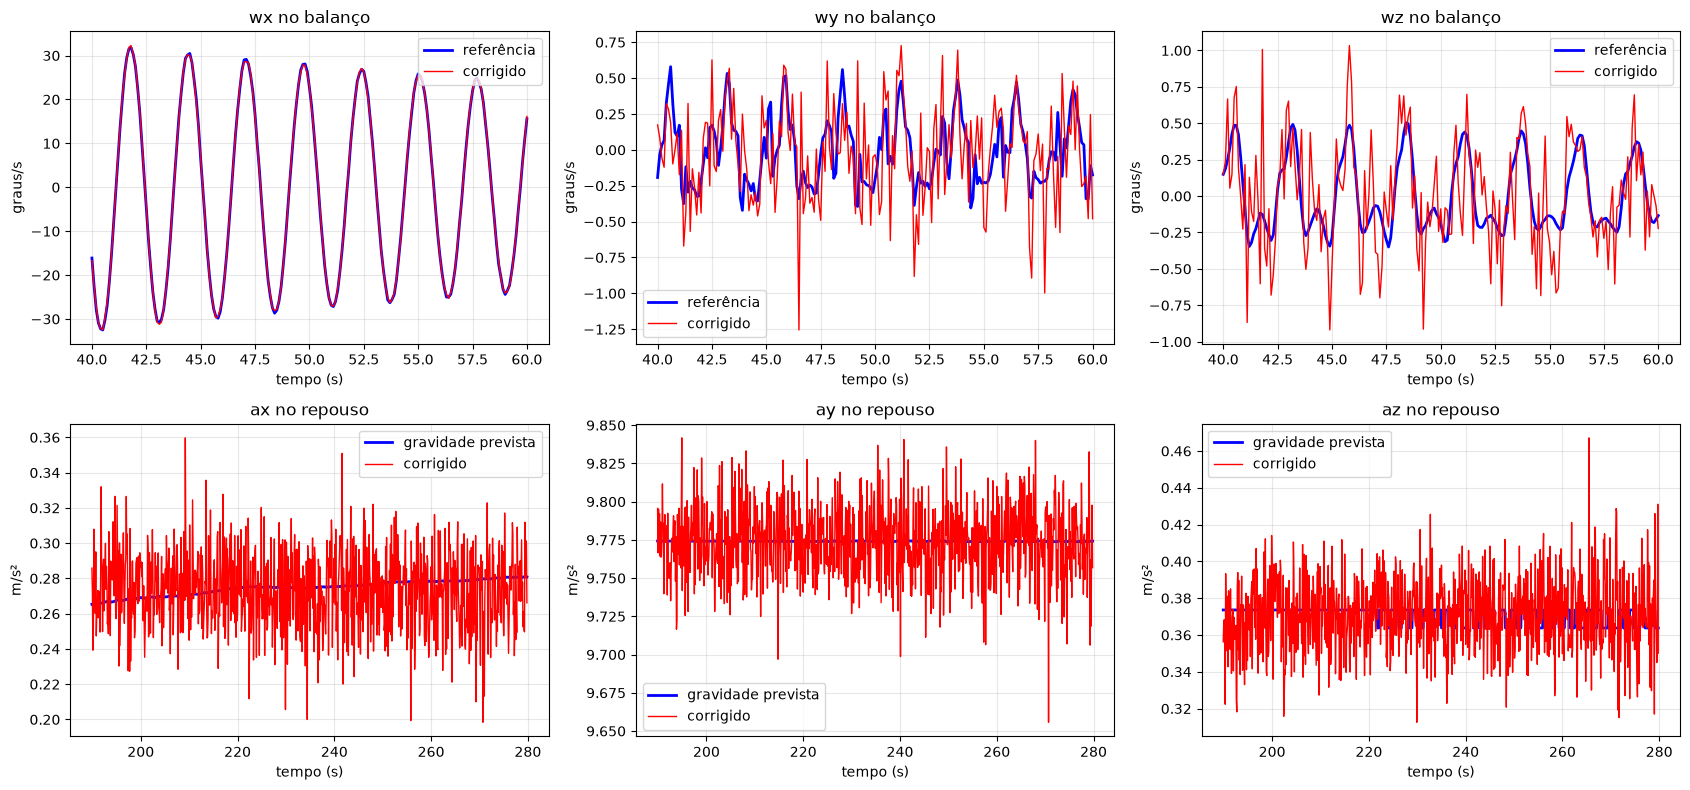

In [8]:
time    = df.time.to_numpy()
window  = (time >= LIMITS[0]) & (time <= LIMITS[1])
rest    = static & (time >= time[static][0] + 10)
gyro    = corrections['gyro'].apply(measured['gyro'], df.tmp.to_numpy())
accel   = corrections['accel'].apply(measured['accel'], df.tmp.to_numpy())

plt.figure(figsize=(17, 8))
for i, var in enumerate(TRIADS['gyro']):
    plt.subplot(2, 3, i + 1)
    plt.plot(time[window], expected['gyro'][window, i], label='referência', color='blue', linewidth=2)
    plt.plot(time[window], gyro[window, i], label='corrigido', color='red', linewidth=1)
    plt.title(f'{var} no balanço'); plt.xlabel('tempo (s)'); plt.ylabel('graus/s'); plt.grid(alpha=0.3); plt.legend()

for i, var in enumerate(TRIADS['accel']):
    plt.subplot(2, 3, i + 4)
    plt.plot(time[rest], expected['accel'][rest, i], label='gravidade prevista', color='blue', linewidth=2)
    plt.plot(time[rest], accel[rest, i], label='corrigido', color='red', linewidth=1)
    plt.title(f'{var} no repouso'); plt.xlabel('tempo (s)'); plt.ylabel('m/s²'); plt.grid(alpha=0.3); plt.legend()

plt.tight_layout()
plt.show()

# SALVANDO OS DADOS CORRIGIDOS
- O corrigido sai do filtrado e o `_raw` do cru, os dois nos eixos do navio: a diferença entre eles é só o que a filtragem tirou
- `corrected.csv` é a entrada das três estratégias do `3 - Attitude` e do `4 - Heave`

In [9]:
for name, axes in TRIADS.items():
    for suffix in ['', '_raw']:
        columns     = [f'{var}{suffix}' for var in axes]
        df[columns] = corrections[name].apply(df[columns].to_numpy(), df.tmp.to_numpy())

df.to_csv(f'{RESULTS}/corrected.csv', index=None)
df

,time,static,tmp,ax_raw,ay_raw,az_raw,wx_raw,wy_raw,wz_raw,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz,ax,ay,az,wx,wy,wz
0,0.0,False,53.0,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353,18.043,1.525,2.936,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353
1,0.1,False,52.9,0.322763,11.616255,0.465550,-58.370550,0.526529,0.469984,12.732,0.742,2.725,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249,0.236557,11.498772,0.493097,-58.326192,0.580323,0.383267
2,0.2,False,53.1,0.054475,12.909180,2.212130,-67.673557,1.310224,-0.457550,6.586,-0.119,2.578,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578,0.121950,12.716274,1.420537,-67.640523,0.887947,-0.479057
3,0.3,False,53.3,0.462140,12.402011,0.398955,-67.729401,0.447877,1.025895,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268,0.233087,12.446751,0.857032,-67.714281,0.680188,0.909507
4,0.4,False,52.9,0.341902,12.355553,0.135763,-66.910249,1.354344,0.655885,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216,0.287146,12.369719,0.464970,-66.916715,1.010186,0.684956
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,55.5,0.311862,9.761934,0.363773,-0.113186,-0.245025,0.209067,-2.510,-1.368,5.289,1.644962,-92.131613,6.371291,0.026304,0.007389,0.002918,0.274240,9.755749,0.368467,-0.108781,-0.135746,0.175447
1796,279.5,True,55.6,0.280704,9.718630,0.345009,-0.091229,0.035855,-0.002447,-2.509,-1.368,5.289,1.645535,-92.131613,6.371291,-0.006860,0.005699,-0.000058,0.276545,9.723646,0.355675,-0.093128,-0.053090,0.011786
1797,279.6,True,55.4,0.301398,9.769912,0.349907,-0.112026,-0.399112,-0.504854,-2.506,-1.367,5.291,1.644962,-92.131613,6.371291,0.001138,-0.030184,-0.002684,0.281426,9.763755,0.351283,-0.116659,-0.223368,-0.467062
1798,279.7,True,55.6,0.300161,9.797726,0.431037,0.091242,0.143646,-0.128904,-2.506,-1.367,5.289,1.645535,-92.131613,6.377020,-0.002625,-0.056662,0.004405,0.281160,9.792971,0.393126,0.093310,-0.042774,-0.151325


In [10]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('correction_')]
index  = len(saved) + 1

output = f'Backup/correction_{index}'
os.makedirs(output, exist_ok=True)

results = {
    'mount':   Rotation.from_matrix(C).as_euler('xyz', degrees=True).tolist(),
    'align':   ALIGN,
    'T0':      T0,
    'triads':  {name: correction.info() for name, correction in corrections.items()},
    'metrics': {name: correction.get() for name, correction in corrections.items()},
    'search':  {'excitation': EXCITATION, 'thermal': THERMAL, 'gravity': GRAVITY},
    'dataset': {'path': SOURCE, 'samples': len(df), 'static': int(static.sum())}
}

record = {
    'strategy': 'correction',
    'backup':   f'2 - Correction/{output}',
    'metrics':  results['metrics']
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
pd.Series(record).to_json(f'{RESULTS}/correction.json', indent=4)
print(output, '->', f'{RESULTS}/correction.json')
record

Backup/correction_3 -> ../Dataset/test1/results/correction.json


{'strategy': 'correction',
 'backup': '2 - Correction/Backup/correction_3',
 'metrics': {'accel': {'antes': [0.09711199305906636,
    0.024232883895404067,
    0.02041537532047234],
   'depois': [0.022801703989937323,
    0.024062596295379178,
    0.020361004104650055]},
  'gyro': {'antes': [0.43595531189252906,
    0.32809985354775645,
    0.2776034704387418],
   'depois': [0.42363713226745264, 0.26915530318478453, 0.2724337383913059]}}}

# EXPORTANDO PARA O FIRMWARE
- `CORRECTION_M[0]` e `[1]` são as matrizes do acelerômetro e do giroscópio: linha é eixo do navio, coluna é eixo do Kernel
- O firmware aplica a correção depois do pré-filtro, sobre o sinal na escala do ICD, que é a do `SCALE_MODE` em que o ensaio foi gravado

In [11]:
FIRMWARE = '../../Hardware/Embedded/Main/objects/processing/correction'

toMatrix = lambda M: '{' + ', '.join('{' + ', '.join(f'{value:.8f}f' for value in row) + '}' for row in M) + '}'
toVector = lambda v: '{' + ', '.join(f'{value:.8e}f' for value in v) + '}'
accel    = corrections['accel']
gyro     = corrections['gyro']

header = f'''#ifndef CORRECTION_CONFIG_H
#define CORRECTION_CONFIG_H

// GERADO POR Calibration/2 - Correction/1 - Model.ipynb EM {datetime.date.today():%d/%m/%Y}
#define CORRECTION_T0 {T0:.3f}f    // graus C de referencia do termo termico

static const float CORRECTION_M[2][3][3] = {{
\t{toMatrix(accel.M)},    // acelerometro: linha = eixo do navio, coluna = eixo do Kernel
\t{toMatrix(gyro.M)}     // giroscopio
}};

static const float CORRECTION_C[2][3] = {{{toVector(accel.c)}, {toVector(gyro.c)}}};    // vies em m/s^2 e graus/s
static const float CORRECTION_K[2][3] = {{{toVector(accel.k)}, {toVector(gyro.k)}}};    // por graus C

#endif
'''

open(f'{FIRMWARE}/config.h', 'w').write(header)
print(header)

#ifndef CORRECTION_CONFIG_H
#define CORRECTION_CONFIG_H

// GERADO POR Calibration/2 - Correction/1 - Model.ipynb EM 16/10/2026
#define CORRECTION_T0 54.448f    // graus C de referencia do termo termico

static const float CORRECTION_M[2][3][3] = {
	{{0.98955804f, 0.13000589f, 0.00045352f}, {0.00063462f, -0.00849339f, 0.99764257f}, {0.12981775f, -0.98990654f, -0.00857929f}},    // acelerometro: linha = eixo do navio, coluna = eixo do Kernel
	{{0.98621125f, 0.12851017f, 0.00145039f}, {0.00997993f, -0.00800420f, 0.98205890f}, {0.12800558f, -0.97318002f, -0.00768652f}}     // giroscopio
};

static const float CORRECTION_C[2][3] = {{9.50862503e-02f, 2.03593656e-02f, -2.05440608e-04f}, {7.27234294e-03f, 6.86504931e-04f, 5.74786091e-03f}};    // vies em m/s^2 e graus/s
static const float CORRECTION_K[2][3] = {{0.00000000e+00f, 0.00000000e+00f, 0.00000000e+00f}, {0.00000000e+00f, 0.00000000e+00f, 0.00000000e+00f}};    // por graus C

#endif



# EXPORTANDO O ALIGN DO ENSAIO
- A correção vale para o Kernel no align em que o ensaio foi gravado. Instalado noutra posição, com outro align, o `processing/align` do firmware lê o align do Kernel no boot e gira a correção: a entrada volta aos eixos do ensaio por $Q^\top$ e a saída vai aos eixos do navio por $F$

$$Q = R_{agora}\,R_{ensaio}^\top \qquad F = P\,Q\,P^\top \qquad x_{navio} = F\,\big(M\,Q^\top x + c + k\,\Delta T\big)$$

- $R$ é a orientação do Kernel no navio pelos ângulos do align (ICD, Apêndice B) e $P$ é a montagem $C$ arredondada para eixos inteiros
- O align do ensaio vem de `Dataset/testN/info.json` (`"align": [proa, pitch, roll]`). Sem ele, ou com a montagem longe de eixos inteiros, o firmware não gira nada

In [12]:
FOLDER = '../../Hardware/Embedded/Main/objects/processing/align'
P      = np.round(C) + 0.0
whole  = np.allclose(np.abs(P).sum(axis=0), 1) and np.allclose(np.abs(P).sum(axis=1), 1) and np.abs(C - P).max() < 0.2    # MONTAGEM A MENOS DE ~11 GRAUS DE EIXOS INTEIROS
angles = ALIGN if ALIGN is not None and whole else [np.nan]*3
toAngle = lambda value: 'NAN' if np.isnan(value) else f'{value:.4f}f'

header = f'''#ifndef ALIGN_CONFIG_H
#define ALIGN_CONFIG_H

// GERADO POR Calibration/2 - Correction/1 - Model.ipynb EM {datetime.date.today():%d/%m/%Y}
static const float ALIGN_CALIBRATION[3] = {{{', '.join(toAngle(value) for value in angles)}}};    // proa, pitch e roll do Kernel no ensaio; NAN desliga a rotacao
static const float ALIGN_FRAME[3][3]    = {toMatrix(P)};    // eixos do navio do ensaio nos eixos do Kernel: a montagem arredondada

#endif
'''

open(f'{FOLDER}/config.h', 'w').write(header)
print(header)

#ifndef ALIGN_CONFIG_H
#define ALIGN_CONFIG_H

// GERADO POR Calibration/2 - Correction/1 - Model.ipynb EM 16/10/2026
static const float ALIGN_CALIBRATION[3] = {NAN, NAN, NAN};    // proa, pitch e roll do Kernel no ensaio; NAN desliga a rotacao
static const float ALIGN_FRAME[3][3]    = {{1.00000000f, 0.00000000f, 0.00000000f}, {0.00000000f, 0.00000000f, 1.00000000f}, {0.00000000f, -1.00000000f, 0.00000000f}};    // eixos do navio do ensaio nos eixos do Kernel: a montagem arredondada

#endif

